# 543. Diameter of Binary Tree
**Difficulty:** 🟢 Easy · **Topic:** Trees · **Pattern:** [DFS Height and Global](README.md) · **LeetCode:** https://leetcode.com/problems/diameter-of-binary-tree/

## 💡 Concepts

**Core concept(s):** post-order DFS that **returns** a node's height while **updating** a global best answer.

**Why it applies here:**
- The longest path either bends at some node or it doesn't exist at all — every path has one highest node where it turns.
- The longest path bending at node `x` uses `height(x.left) + height(x.right)` edges.
- So the answer is the max of that sum over every node, and each node only needs its children's heights.
- But a parent needs a **height** (one arm) from the child, not the child's diameter (two arms). The DFS returns one and records the other in a global variable.

**Key intuition:**
- At each node: **record** `left + right` as a candidate answer, **return** `1 + max(left, right)` to the parent.
- The diameter does not have to pass through the root.

---

### 📚 What is a Binary Tree?
- A **binary tree** is a set of nodes in a branching shape.
- Each node holds a value and up to two children: **left** and **right**.
- The top node is the **root**; nodes with no children are **leaves**.
- **Height** of a node = the number of nodes on the longest path from it down to a leaf (an empty tree has height `0`).
- **In Python:** a small `TreeNode` class with `.val`, `.left`, `.right`.

### 📚 What is DFS (Depth-First Search) / Recursion?
- **DFS** dives down one branch as far as it can, then backs up and tries the next branch.
- It is usually written with **recursion**: a function that calls itself on each child.
- Each pending call waits on the **call stack**, so the stack is as deep as the tree is tall.
- **Complexity:** each node is visited once → **O(n)** time; **O(h)** extra space for the call stack (`h` = height).
- **In Python:** a plain recursive function; `sys.setrecursionlimit` raises the default depth limit (1000) for very tall trees.

### 📚 What is Post-order DFS?
- **Post-order** means: handle the left child, then the right child, and only then the node itself.
- It is the natural order whenever a node's answer depends on its children's answers.
- Mental picture: information flows **bottom-up**, from the leaves to the root.

### 📚 What is a "global" / `nonlocal` variable in recursion?
- A variable that lives **outside** the recursive function, so every call reads and writes the same one.
- In Python, an inner function can update an outer variable after declaring it `nonlocal best`.
- It holds the best answer seen anywhere in the tree, while the return value stays free for the height.

---

**Prerequisite knowledge:**
- Computing the height (max depth) of a tree recursively — see Maximum Depth of Binary Tree.

## 📝 Problem

Given the root of a binary tree, return the length of its **diameter**: the number of **edges** on the longest path between any two nodes. The path may or may not pass through the root.

**Examples**
```
[1,2,3,4,5] -> 3   (4 -> 2 -> 1 -> 3, or 5 -> 2 -> 1 -> 3)
[1,2]       -> 1
```

**Constraints:** `1 <= number of nodes <= 10^4`, `-100 <= Node.val <= 100`.

> Two approaches: recompute heights at every node, then one DFS that returns height and updates a global best.

In [1]:
from typing import Optional, List
from collections import deque

class TreeNode:
    """A single node of a binary tree: a value plus links to up to two children."""
    def __init__(self, val=0, left=None, right=None):
        self.val = val                     # the number stored at this node
        self.left = left                   # the left child (or None)
        self.right = right                 # the right child (or None)

def build_tree(values):
    """Build a tree from a level-order list, LeetCode style (None = missing child)."""
    if not values or values[0] is None:
        return None
    root = TreeNode(values[0]); q = deque([root]); i = 1
    while q and i < len(values):
        node = q.popleft()                 # the parent we're attaching children to
        if i < len(values):                # attach the left child (if present)
            if values[i] is not None:
                node.left = TreeNode(values[i]); q.append(node.left)
            i += 1
        if i < len(values):                # attach the right child (if present)
            if values[i] is not None:
                node.right = TreeNode(values[i]); q.append(node.right)
            i += 1
    return root

def build_balanced(n):
    """Balanced BST holding 1..n (height ~log n) — used by the benchmark."""
    def helper(lo, hi):
        if lo > hi:
            return None
        mid = (lo + hi) // 2               # middle value becomes the subtree's root
        node = TreeNode(mid)
        node.left = helper(lo, mid - 1)    # smaller values go left
        node.right = helper(mid + 1, hi)   # larger values go right
        return node
    return helper(1, n)

def preorder(root):
    """Collect values in preorder: node, then left, then right."""
    out = []
    def go(n):
        if not n: return
        out.append(n.val); go(n.left); go(n.right)
    go(root); return out

def inorder(root):
    """Collect values in inorder: left, then node, then right (sorted for a BST)."""
    out = []
    def go(n):
        if not n: return
        go(n.left); out.append(n.val); go(n.right)
    go(root); return out

def same_shape(a, b):
    """True if two trees have identical shape and values."""
    if not a and not b: return True        # both empty -> match
    if not a or not b or a.val != b.val: return False  # one empty, or values differ
    return same_shape(a.left, b.left) and same_shape(a.right, b.right)

### Approach 1 — Recompute Heights at Every Node (brute force)

**Idea:**
1. Write a plain `height(node)` function.
2. At each node, the longest path that bends there has `height(left) + height(right)` edges.
3. Recurse into every node and keep the biggest such value.
4. Each `height` call re-walks a whole subtree that other calls already walked.

**Time:** `O(n²)` worst case — on a one-sided chain the height calls cost `n-1, n-2, …, 1` steps. On a balanced tree it is `O(n log n)`.

**Space:** `O(h)` for the recursion stack.

In [2]:
def height(node: Optional[TreeNode]) -> int:
    """Number of nodes on the longest downward path from node (0 for an empty tree)."""
    if not node:
        return 0
    return 1 + max(height(node.left), height(node.right))

def diameter_brute(root: Optional[TreeNode]) -> int:
    if not root:
        return 0
    # Longest path bending at root: left height + right height edges (heights re-measured here).
    through_root = height(root.left) + height(root.right)
    # ...or the best path lies entirely inside one subtree.
    return max(through_root, diameter_brute(root.left), diameter_brute(root.right))

### Approach 2 — One DFS: Return Height, Update a Global Best (optimal)

**Idea:**
1. Keep a variable `best = 0` outside the recursion.
2. A post-order DFS `depth(node)` gets `left` and `right` heights from its children.
3. **Side effect:** `best = max(best, left + right)` — the path bending at this node.
4. **Return:** `1 + max(left, right)` — the parent can only extend **one** arm.
5. After the DFS finishes, `best` is the diameter.

**Time:** `O(n)` — each node is visited once.

**Space:** `O(h)` for the recursion stack.

In [3]:
def diameter_optimal(root: Optional[TreeNode]) -> int:
    best = 0                               # longest path (in edges) seen anywhere so far
    def depth(node):                       # returns the height of node's subtree
        nonlocal best
        if not node:
            return 0
        left = depth(node.left)
        right = depth(node.right)
        best = max(best, left + right)     # side effect: the path that bends at this node
        return 1 + max(left, right)        # the parent can only use ONE arm
    depth(root)
    return best

In [4]:
# Correctness check
tests = [
    ([1, 2, 3, 4, 5], 3),
    ([1, 2], 1),
    ([1], 0),
    ([], 0),
    ([1, 2, None, 3, 4, 5, None, None, 6], 4),   # longest path 5-3-2-4-6 skips the root
    ([1, None, 2, None, 3, None, 4], 3),          # a chain of 4 nodes
]
for vals, exp in tests:
    root = build_tree(vals)
    a, b = diameter_brute(root), diameter_optimal(root)
    print(f"{vals} -> brute={a}, optimal={b} | expected={exp}")
    assert a == b == exp, "mismatch!"
print("\nAll tests passed")

[1, 2, 3, 4, 5] -> brute=3, optimal=3 | expected=3
[1, 2] -> brute=1, optimal=1 | expected=1
[1] -> brute=0, optimal=0 | expected=0
[] -> brute=0, optimal=0 | expected=0
[1, 2, None, 3, 4, 5, None, None, 6] -> brute=4, optimal=4 | expected=4
[1, None, 2, None, 3, None, 4] -> brute=3, optimal=3 | expected=3

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on trees of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | a bit over **2×** |
| `O(n²)`       | ≈ **4×** |

The brute force's worst case is a **one-sided chain** (every node has only a left child): the `height` calls cost `n-1 + n-2 + … + 1 ≈ n²/2` steps. A chain of `n` nodes is `n` calls deep, so the cell raises Python's recursion limit first. Expect the brute ratio near **4×** and the optimal near **2×**.


brute   O(n^2)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      250 |       3.47 |           n/a
      500 |      14.06 |         4.06x


     1000 |      54.22 |         3.86x


     2000 |     234.26 |         4.32x

optimal O(n)  
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      250 |       0.04 |           n/a
      500 |       0.08 |         2.03x
     1000 |       0.17 |         2.10x
     2000 |       0.40 |         2.35x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


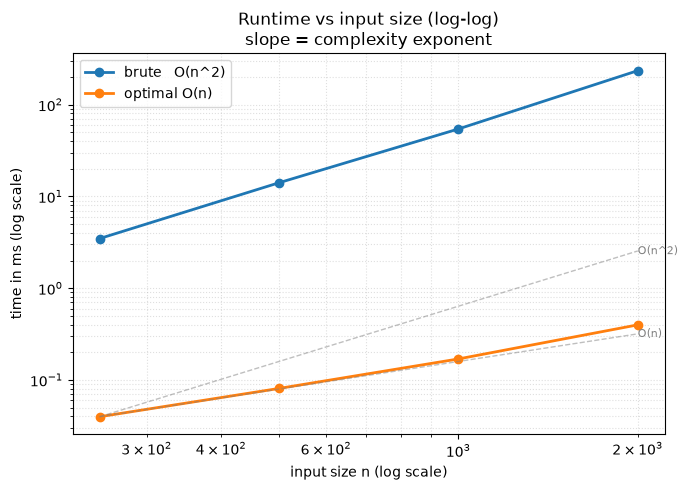

{'brute   O(n^2)': [3.4672910114750266,
  14.061708003282547,
  54.216999909840524,
  234.26479194313288],
 'optimal O(n)  ': [0.03970798570662737,
  0.08074997458606958,
  0.1692500663921237,
  0.3981250338256359]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark
sys.setrecursionlimit(20000)              # a chain of n nodes recurses n levels deep

def build_chain(n):
    """Left-leaning chain 1 -> 2 -> ... -> n (height n): the brute force's worst case."""
    root = node = TreeNode(1)
    for v in range(2, n + 1):
        node.left = TreeNode(v)
        node = node.left
    return root

def make_worst_case(n):
    return (build_chain(n),)
solutions = {
    "brute   O(n^2)": diameter_brute,
    "optimal O(n)  ": diameter_optimal,
}
sizes = [250, 500, 1000, 2000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [DFS Height and Global](README.md) — the DFS returns each node's height and, as a side effect, updates a global `best` with `left + right`, the path bending at that node.
- **Return one thing, track another:** what the parent needs (one arm: a height) differs from the answer (two arms: a diameter), so the answer goes in a `nonlocal`/global variable.
- **Every path has a highest node:** checking "the path that bends here" at every node covers every possible path, including ones that skip the root.
- **Signal:** "longest path between any two nodes", "may or may not pass through the root", "best path in a tree".
- **Related problems:** Balanced Binary Tree, Binary Tree Maximum Path Sum, Longest Univalue Path.
- **Common pitfalls:** (1) returning `left + right` to the parent — a parent's path cannot use both arms of a child; (2) only checking the root's `left + right`; (3) counting nodes instead of edges (the diameter counts edges).